8.846873462791343 1.228140703517588


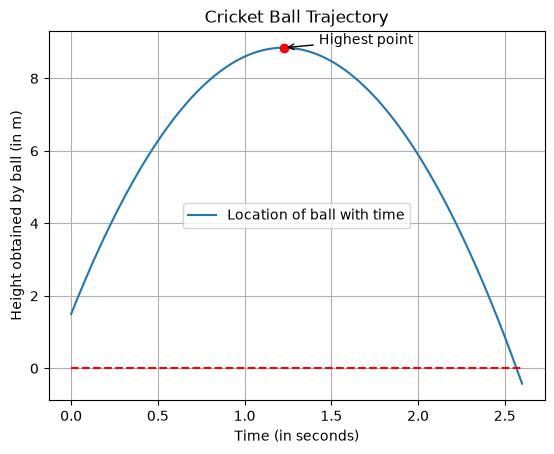

2.573869346733668


In [26]:
import matplotlib.pyplot as plt
import numpy as np

time = np.linspace(0,2.6,200, dtype= 'float')
y = []
y_0 = []
for i in time:
        y.append((1.5) + (12* i) - (4.9 * (i**2)))
        y_0.append(0)
y_arr = np.array(y)
y_new = np.array(y_0)

y0 = np.max(y_arr)
x0 = time[np.argmax(y)]

print(y0, x0)

plt.plot(time, y_arr, label ='Location of ball with time')
plt.plot(time, y_new, color = 'red', linestyle='--')
plt.annotate("Highest point", xy=(x0, y0), xytext=(x0+0.2, y0+0.1), arrowprops=dict(arrowstyle="->") )
plt.plot(x0,y0, color = 'red', marker= 'o')
plt.title('Cricket Ball Trajectory')
plt.xlabel('Time (in seconds)')
plt.ylabel('Height obtained by ball (in m)')
plt.grid(True)
plt.legend()
plt.show()

t = 0
for i in range(0,200,1):
    if(y[i]<0.0):
        t = time[i]
        break
    else:
        pass
print(t)

-4.9*t**2 + 12*t + 1.5

12 - 9.8*t

-9.80000000000000

[-0.119198303786247, 2.56817789562298]

[1.22448979591837]

8.84693877551020

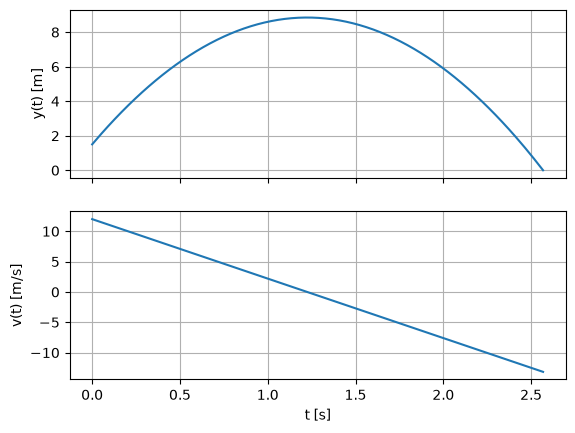

In [30]:
import matplotlib.pyplot as plt
import numpy as np
import sympy as sp
from IPython.display import display

t = sp.symbols('t')
y = (1.5) + (12* t) - (4.9 * (t**2))
display(y)
v = sp.diff(y,t)
display(v)
a = sp.diff(v,t)
display(a)                                    #### Value matches with gravity

t_distance = sp.solve(y,t)
t_velocity = sp.solve(v,t)
display(t_distance)
display(t_velocity)
display(y.subs(t,t_velocity[0]))   ###Value obtained is almost same


v_func = sp.lambdify(t, v, 'numpy')
y_func = sp.lambdify(t, y, 'numpy')

t_end = max(t_distance)          # 2.568 s
t_vals = np.linspace(0, float(t_end), 200)

fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True)

ax1.plot(t_vals, y_func(t_vals))
ax1.set_ylabel('y(t) [m]')
ax1.grid(True)

ax2.plot(t_vals, v_func(t_vals))
ax2.set_ylabel('v(t) [m/s]')
ax2.set_xlabel('t [s]')
ax2.grid(True)

plt.show()

2*t*exp(-t/5)

(-10*t - 50)*exp(-t/5) + 50

-(-10*t - 50)*exp(-t/5)/5 - 10*exp(-t/5)

0

50 - 250*exp(-4)

45.4210902778165

5

14.9715417350106


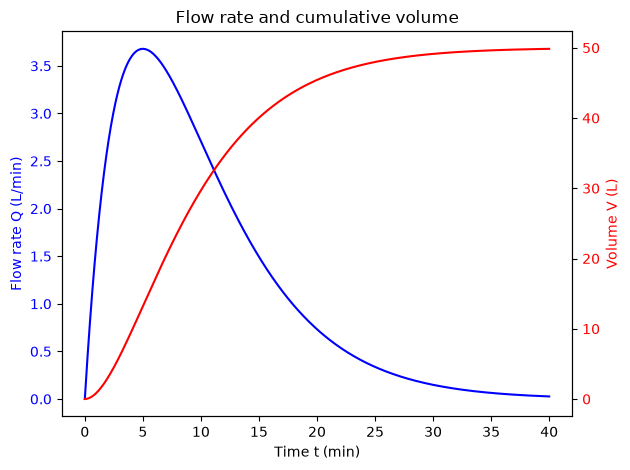

In [41]:
import sympy as sp
import numpy as np
import math
import matplotlib.pyplot as plt
from IPython.display import display

t = sp.symbols('t')
Q = (2* t *(sp.exp(-t/5)))
display(Q)

integ = sp.integrate(Q,(t,0,t))
display(integ)

differ = sp.diff(integ,t)
display(differ)

result = sp.simplify(Q - differ)
display(result)

vol = sp.integrate(Q,(t,0,20))
display(vol)
display(vol.evalf())

flowrate_time = sp.solve(sp.diff(Q,t),t)
display(flowrate_time[0])

time = np.linspace(0,40,1000)

vol_max = 40.0
equation = integ - vol_max
solution = sp.nsolve(equation,t,15.0)
print(solution)

Q_f = sp.lambdify(t, Q, 'numpy')
V_f = sp.lambdify(t, integ, 'numpy')

fig, ax = plt.subplots()
ax.plot(time, Q_f(time), color='blue')
ax.set_xlabel('Time t (min)')
ax.set_ylabel('Flow rate Q (L/min)', color='blue')
ax.tick_params(axis='y', labelcolor='blue')

ax2 = ax.twinx()                      # second y-axis, shared x-axis
ax2.plot(time, V_f(time), color='red')
ax2.set_ylabel('Volume V (L)', color='red')
ax2.tick_params(axis='y', labelcolor='red')

ax.set_title('Flow rate and cumulative volume')
fig.tight_layout()
plt.show()
##### A3 4th part remains unsolved

x
-x**3/6 + x
x**5/120 - x**3/6 + x


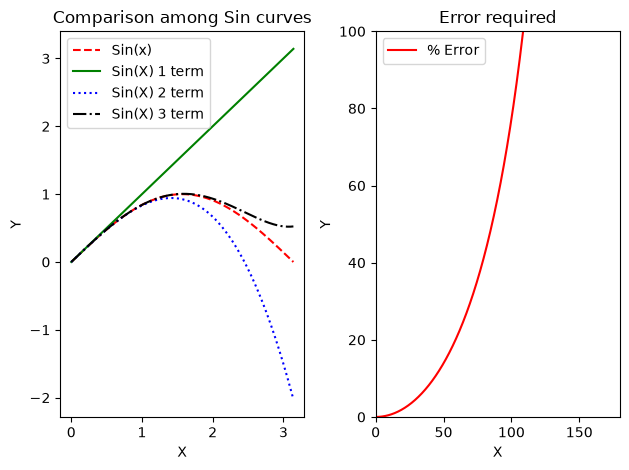

13
57


In [36]:
import sympy as sp
import numpy as np

x = sp.symbols('x')
sin_series_1 = sp.series(sp.sin(x), x, 0, 2).removeO()
print(sin_series_1)
sin_series_2 = sp.series(sp.sin(x), x, 0, 4).removeO()
print(sin_series_2)
sin_series_3 = sp.series(sp.sin(x), x, 0, 6).removeO()
print(sin_series_3)

f1 = sp.lambdify(x, sin_series_1, 'numpy')
f2 = sp.lambdify(x, sin_series_2, 'numpy')
f3 = sp.lambdify(x, sin_series_3, 'numpy')

interval = np.linspace(0,np.pi,1000)

plt.subplot(1,2,1)
plt.plot(interval,np.sin(interval), "r--", label = "Sin(x)")
plt.plot(interval,f1(interval), "g-", label = "Sin(X) 1 term")
plt.plot(interval, f2(interval), "b:", label = "Sin(X) 2 term")
plt.plot(interval, f3(interval), "k-.", label = "Sin(X) 3 term")
plt.xlabel("X")
plt.ylabel("Y")
plt.title("Comparison among Sin curves")
plt.legend()

error = [0]
for i in interval:
    if i==0:
        pass
    else:
        error.append(np.abs((f1(i) - np.sin(i))*100/np.sin(i)))

interval_degrees = np.linspace(0,180,1000)
error_arr = np.array(error)

plt.subplot(1,2,2)
plt.plot(interval_degrees,error_arr, "r-", label = "% Error")
plt.xlabel("X")
plt.ylabel("Y")
plt.ylim(0,100)
plt.xlim(0,180)
plt.title("Error required")
plt.legend()

plt.tight_layout()
plt.show()


for i in range(0,1000,1):
    if error[i]>1.0:
        print(int(interval_degrees[i-1]))
        break
    else:
        continue

error2 = [0]
for i in interval:
    if i==0:
        pass
    else:
        error2.append(np.abs((f2(i) - np.sin(i))*100/np.sin(i)))

error_arr2 = np.array(error)


for i in range(0,1000,1):
    if error2[i]>1.0:
        print(int(interval_degrees[i-1]))
        break
    else:
        continue

################  13 degrees is the maximum angle that should be assumed 